In [50]:
# Import libraries for data handling, plotting, and linear regression
import pandas as pd 
import matplotlib.pyplot as plt 
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split


In [51]:
# read the csv file (dataset)
df=pd.read_csv("california_housing_train.csv")

In [52]:
# Display the first five rows of the dataset
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0


In [53]:
# Count missing values in each column
df.isnull().sum()

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
dtype: int64

In [54]:
# Count duplicate rows in the dataset
df.duplicated().sum()

np.int64(0)

In [55]:
# Show correlations between the numeric columns
df.corr()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
longitude,1.000000,-0.925208,-0.114250,0.047010,0.071802,0.101674,0.059628,-0.015485,-0.044982
latitude,-0.925208,1.000000,0.016454,-0.038773,-0.069373,-0.111261,-0.074902,-0.080303,-0.144917
housing_median_age,-0.114250,0.016454,1.000000,-0.360984,-0.320434,-0.295890,-0.302754,-0.115932,0.106758
total_rooms,0.047010,-0.038773,-0.360984,1.000000,0.928403,0.860170,0.919018,0.195383,0.130991
total_bedrooms,0.071802,-0.069373,-0.320434,0.928403,1.000000,0.881169,0.980920,-0.013495,0.045783
population,0.101674,-0.111261,-0.295890,0.860170,0.881169,1.000000,0.909247,-0.000638,-0.027850
households,0.059628,-0.074902,-0.302754,0.919018,0.980920,0.909247,1.000000,0.007644,0.061031
median_income,-0.015485,-0.080303,-0.115932,0.195383,-0.013495,-0.000638,0.007644,1.000000,0.691871
median_house_value,-0.044982,-0.144917,0.106758,0.130991,0.045783,-0.027850,0.061031,0.691871,1.000000


In [56]:
# Select the house features as inputs and house value as the target
x=df[["longitude","latitude","housing_median_age","total_rooms","total_bedrooms","population","households","median_income"]]
y=df['median_house_value']

In [57]:
# Create a linear regression model
model=LinearRegression()

In [58]:
# Split the data into training and testing sets
x_train,x_test,y_train,y_test=train_test_split(x,y,train_size=0.8,random_state=42)

In [59]:
# Train the model using the training data
model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [60]:
# Display the model's intercept
model.intercept_

np.float64(-3652253.134845132)

In [61]:
# Display the coefficient for each input feature
model.coef_

array([-4.34652477e+04, -4.31063044e+04,  1.13172438e+03, -8.84326062e+00,
        1.13707973e+02, -3.56570769e+01,  4.51475550e+01,  4.01947263e+04])

In [62]:
# Predict house values for the training inputs
ytrain_predict=model.predict(x_train)

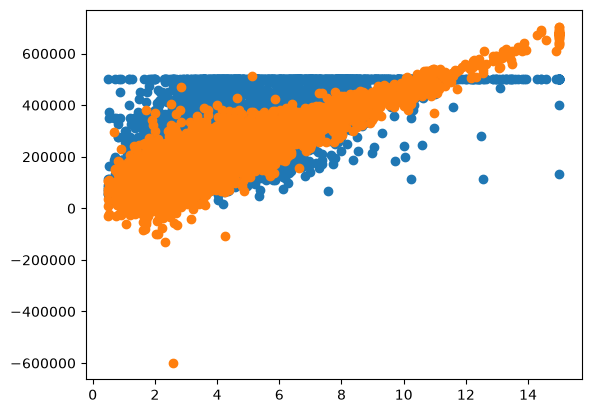

In [70]:
# Plot actual and predicted house values against the selected input feature
feature="median_income"
plt.scatter(x_train[feature], y_train,label='actual value')
plt.scatter(x_train[feature], ytrain_predict,label='predicted value')


In [78]:
# Predict house values for the testing inputs
ytest_predict=model.predict(x_test)

In [91]:
# Enter a new house's feature values and predict its median value
new_house = pd.DataFrame([{
    "longitude": -122.23,
    "latitude": 37.88,
    "housing_median_age": 41,
    "total_rooms": 880,
    "total_bedrooms": 129,
    "population": 322,
    "households": 126,
    "median_income": 8.325
}])

predicted_value = model.predict(new_house)[0]
print(f"Predicted median house value: ${predicted_value:,.0f}")

Predicted median house value: $409,752
